Imports

In [83]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import shap

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error

from xgboost import XGBRegressor

C:\Users\ltrav\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [65]:
from dataset_create import charger
df = charger()
df.head()

,axe,arc_id,datetime_utc,debit,occupation,etat_trafic,etat_arc_code,ligne_absente,source,etat_arc,datetime
0,Champs-Elysees,4264,2014-01-01 00:00:00+00:00,4.0,0.00000,Fluide,3.0,False,old_data,NaN,2014-01-01 01:00:00+01:00
1,Champs-Elysees,4264,2014-01-01 01:00:00+00:00,21.0,0.10445,Fluide,3.0,False,old_data,NaN,2014-01-01 02:00:00+01:00
2,Champs-Elysees,4264,2014-01-01 02:00:00+00:00,417.0,6.12667,Fluide,3.0,False,old_data,NaN,2014-01-01 03:00:00+01:00
3,Champs-Elysees,4264,2014-01-01 03:00:00+00:00,1089.0,14.39890,Fluide,3.0,False,old_data,NaN,2014-01-01 04:00:00+01:00
4,Champs-Elysees,4264,2014-01-01 04:00:00+00:00,943.0,10.35220,Fluide,3.0,False,old_data,NaN,2014-01-01 05:00:00+01:00


Ajout features

In [66]:
df["heure"] = df["datetime"].dt.hour
df["jour_semaine"] = df["datetime"].dt.dayofweek
df["jour_mois"] = df["datetime"].dt.day
df["mois"] = df["datetime"].dt.month
df["weekend"] = (df["jour_semaine"] >= 5).astype(int)

In [67]:
# Variables cycliques
df["heure_sin"] = np.sin(2 * np.pi * df["heure"] / 24)
df["heure_cos"] = np.cos(2 * np.pi * df["heure"] / 24)

df["jour_sin"] = np.sin(2 * np.pi * df["jour_semaine"] / 7)
df["jour_cos"] = np.cos(2 * np.pi * df["jour_semaine"] / 7)

Split Train/test

In [68]:
features = [
    "arc_id",
    "heure",
    "jour_semaine",
    "mois",
    "weekend",
    "heure_sin",
    "heure_cos",
    "jour_sin",
    "jour_cos"
]

target_debit = "debit"
target_occupation = "occupation"

In [69]:
categorical_features = ["arc_id"]

numeric_features = [
    col for col in features
    if col not in categorical_features
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "num",
            "passthrough",
            numeric_features
        )
    ]
)

In [70]:
df_model = df.replace([np.inf, -np.inf], np.nan).copy()

df_model_debit = df_model.dropna(subset=features + ["debit"]).copy()
df_model_occupation = df_model.dropna(subset=features + ["occupation"]).copy()

print("Nombre de lignes avant nettoyage :", len(df))
print("Nombre de lignes après nettoyage :", len(df_model))
print("Nombre de NaN restants :", df_model.isna().sum().sum())

Nombre de lignes avant nettoyage : 337464
Nombre de lignes après nettoyage : 337464
Nombre de NaN restants : 429745


In [71]:
df_model_debit = df.replace([np.inf, -np.inf], np.nan)
df_model_debit = df_model_debit.dropna(subset=features + ["debit"]).copy()

df_model_debit = df_model_debit.sort_values("datetime")

dates = sorted(df_model_debit["datetime"].unique())
split_date = dates[int(len(dates) * 0.8)]

train_debit = df_model_debit[df_model_debit["datetime"] < split_date]
test_debit = df_model_debit[df_model_debit["datetime"] >= split_date]

X_train = train_debit[features]
y_train_debit = train_debit["debit"]

X_test = test_debit[features]
y_test_debit = test_debit["debit"]

In [72]:
print("NaN :", y_train_debit.isna().sum())

print("Inf :", np.isinf(y_train_debit).sum())

print("Valeurs uniques :", y_train_debit.nunique())

print(y_train_debit.describe())

NaN : 0
Inf : 0
Valeurs uniques : 2619
count    251640.000000
mean        676.782256
std         496.967832
min           0.000000
25%         303.000000
50%         590.000000
75%         915.000000
max       33272.000000
Name: debit, dtype: float64


XGBoost

In [73]:
def create_model():

    xgb = XGBRegressor(
        n_estimators=500,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    )

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("xgb", xgb)
    ])

    return model

In [74]:
print("df_model :", df_model.shape)
print("train :", train.shape)
print("test :", test.shape)

print("\nX_train :", X_train.shape)
print("X_test :", X_test.shape)

print("\nNombre de arc_id distincts :", X_train["arc_id"].nunique())
print("Valeurs manquantes arc_id :", X_train["arc_id"].isna().sum())

print("\nAperçu arc_id :")
print(X_train["arc_id"].head())

df_model : (337464, 20)
train : (269971, 20)
test : (67493, 20)

X_train : (251640, 9)
X_test : (39225, 9)

Nombre de arc_id distincts : 3
Valeurs manquantes arc_id : 0

Aperçu arc_id :
0         4264
224976     191
112488    5671
1         4264
224977     191
Name: arc_id, dtype: int64


In [75]:
## Débit
model_debit = create_model()

model_debit.fit(X_train, y_train_debit)

,steps,"[('preprocessor', ...), ('xgb', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('cat', ...), ('num', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [76]:
## Préparation des données occupation

df_model_occupation = df.replace([np.inf, -np.inf], np.nan)
df_model_occupation = df_model_occupation.dropna(
    subset=features + ["occupation"]
).copy()

df_model_occupation = df_model_occupation.sort_values("datetime")

dates = sorted(df_model_occupation["datetime"].unique())
split_date = dates[int(len(dates) * 0.8)]

train_occupation = df_model_occupation[
    df_model_occupation["datetime"] < split_date
]

test_occupation = df_model_occupation[
    df_model_occupation["datetime"] >= split_date
]

X_train_occupation = train_occupation[features]
X_test_occupation = test_occupation[features]

y_train_occupation = train_occupation["occupation"]
y_test_occupation = test_occupation["occupation"]

In [78]:
## Occupation
model_occupation = create_model()

model_occupation.fit(X_train_occupation, y_train_occupation)

,steps,"[('preprocessor', ...), ('xgb', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('cat', ...), ('num', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


RMSE

In [80]:
# Prédictions
pred_debit = model_debit.predict(X_test_debit)
pred_occupation = model_occupation.predict(X_test_occupation)

# Calcul des RMSE
rmse_debit = np.sqrt(mean_squared_error(
    y_test_debit,
    pred_debit
))

rmse_occupation = np.sqrt(mean_squared_error(
    y_test_occupation,
    pred_occupation
))

print(f"RMSE débit       : {rmse_debit:.4f}")
print(f"RMSE occupation  : {rmse_occupation:.4f}")

RMSE débit       : 273.3819
RMSE occupation  : 5.3881


In [81]:
# Baseline : prédire la moyenne du jeu d'entraînement

baseline_debit = np.full(
    len(y_test_debit),
    y_train_debit.mean()
)

baseline_occupation = np.full(
    len(y_test_occupation),
    y_train_occupation.mean()
)

rmse_baseline_debit = np.sqrt(
    mean_squared_error(y_test_debit, baseline_debit)
)

rmse_baseline_occupation = np.sqrt(
    mean_squared_error(y_test_occupation, baseline_occupation)
)

print("Comparaison avec la baseline")
print(f"Débit       : XGBoost = {rmse_debit:.2f} | Baseline = {rmse_baseline_debit:.2f}")
print(f"Occupation  : XGBoost = {rmse_occupation:.2f} | Baseline = {rmse_baseline_occupation:.2f}")

Comparaison avec la baseline
Débit       : XGBoost = 273.38 | Baseline = 329.24
Occupation  : XGBoost = 5.39 | Baseline = 8.10


SHAP

In [84]:
def analyser_shap(model, X_test, nom_cible):

    # On prend un échantillon du jeu de test
    X_sample = X_test.sample(
        n=min(1000, len(X_test)),
        random_state=42
    )

    # Récupération du préprocesseur et du modèle XGBoost
    preprocessor = model.named_steps["preprocessor"]
    xgb_model = model.named_steps["xgb"]

    # Transformation des données
    X_transformed = preprocessor.transform(X_sample)

    # Conversion en tableau dense si nécessaire
    if hasattr(X_transformed, "toarray"):
        X_transformed = X_transformed.toarray()

    # Récupération des noms des features après encodage
    feature_names = preprocessor.get_feature_names_out()

    X_shap = pd.DataFrame(
        X_transformed,
        columns=feature_names
    )

    # Calcul des valeurs SHAP
    explainer = shap.TreeExplainer(xgb_model)
    shap_values = explainer(X_shap)

    # Importance globale
    plt.figure()
    shap.plots.bar(shap_values, max_display=15, show=False)
    plt.title(f"Importance des features - {nom_cible}")
    plt.tight_layout()
    plt.show()

    # Summary plot
    plt.figure()
    shap.plots.beeswarm(shap_values, max_display=15, show=False)
    plt.title(f"SHAP Summary - {nom_cible}")
    plt.tight_layout()
    plt.show()

    return shap_values

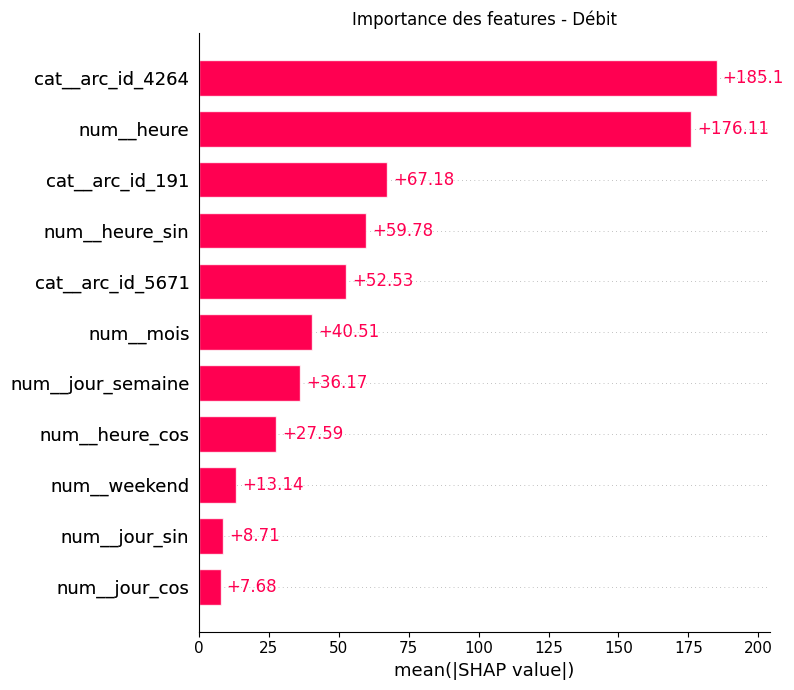

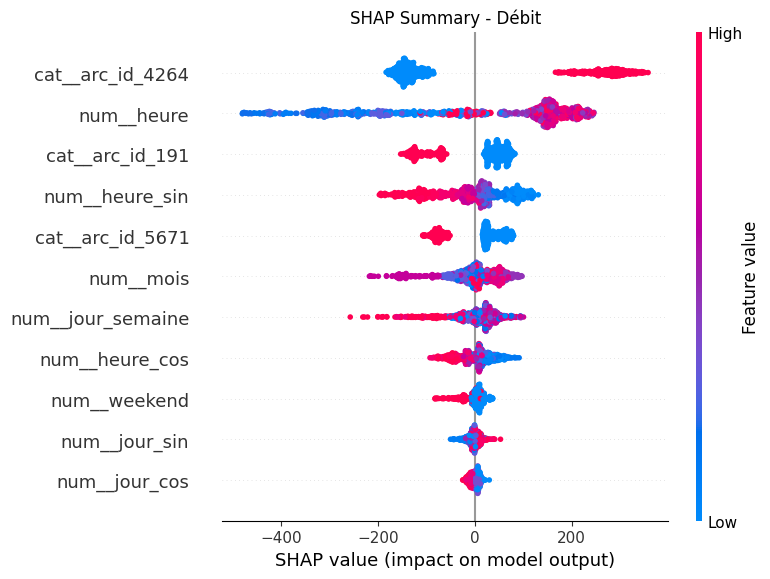

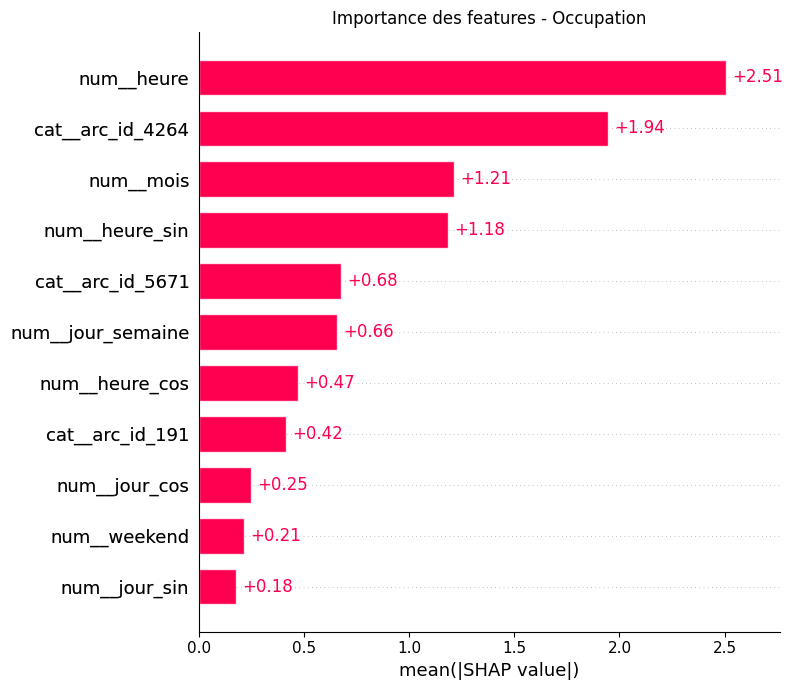

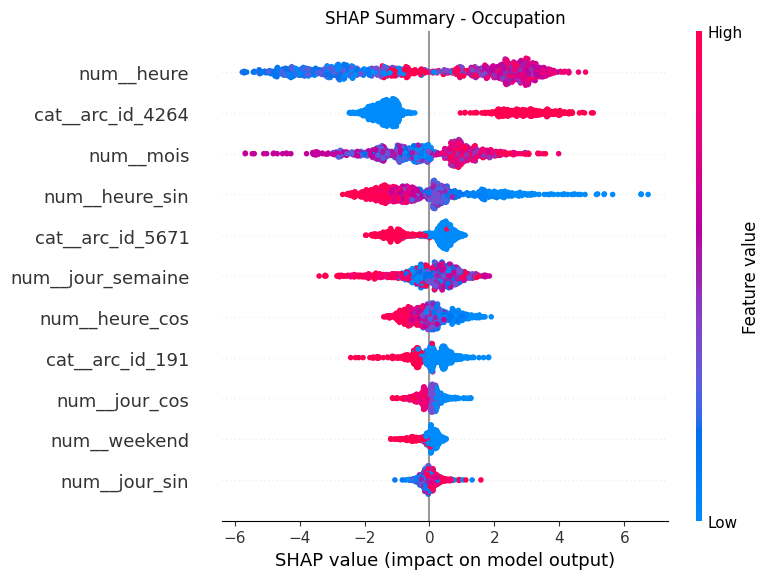

In [85]:
# Analyse du débit
shap_debit = analyser_shap(
    model_debit,
    X_test_debit,
    "Débit"
)

# Analyse de l'occupation
shap_occupation = analyser_shap(
    model_occupation,
    X_test_occupation,
    "Occupation"
)